# Explore heuristic values for an empty maze

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)

## Create the maze representation

Define an empty $10 \times 10$ maze and place the start and goal. The figures retain one-based coordinate labels, while the NumPy array uses zero-based indices.

In [2]:
n = 10
start = np.array([1, 1])
goal = np.array([8, 8])

maze = np.full((n, n), " ", dtype=str)
maze[tuple(start)] = "S"
maze[tuple(goal)] = "G"
maze

array([[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', 'S', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', 'G', ' '],
       [' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']], dtype='<U1')

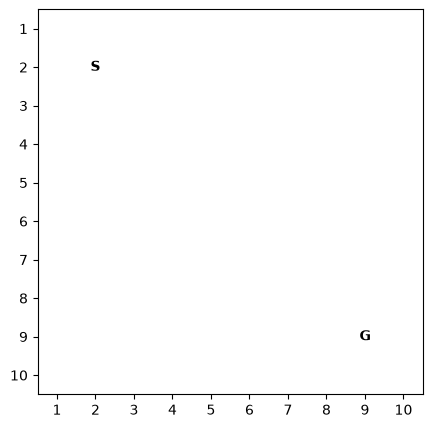

In [3]:
def show_values(values, cmap="YlOrRd_r", colorbar=True):
    """Display values on the maze and mark the start and goal."""
    figure, axis = plt.subplots(figsize=(6, 5))
    image = axis.imshow(values, cmap=cmap, origin="upper")
    axis.set_xticks(range(n), labels=range(1, n + 1))
    axis.set_yticks(range(n), labels=range(1, n + 1))
    axis.text(goal[1], goal[0], "G", ha="center", va="center", fontweight="bold")
    axis.text(start[1], start[0], "S", ha="center", va="center", fontweight="bold")
    if colorbar:
        figure.colorbar(image, ax=axis, label="value")
    plt.show()


show_values(np.zeros((n, n)), cmap="Greys", colorbar=False)

## Greedy Best-First Search: Use Manhattan Distance for $h(n)$

Manhattan distance is also called the $L_1$ norm. It is the difference in x values plus the difference in y values: $L_1(a,b) = |a_x-b_x| + |a_y-b_y|$.

Manhattan distance is a perfect heuristic for the maze: $h(n) = h^*(n)$ and $f(n) = f^*(n)$ (the asterisk represents the optimal value). Calculate $h(n)$.

[[16 15 14 13 12 11 10  9  8  9]
 [15 14 13 12 11 10  9  8  7  8]
 [14 13 12 11 10  9  8  7  6  7]
 [13 12 11 10  9  8  7  6  5  6]
 [12 11 10  9  8  7  6  5  4  5]
 [11 10  9  8  7  6  5  4  3  4]
 [10  9  8  7  6  5  4  3  2  3]
 [ 9  8  7  6  5  4  3  2  1  2]
 [ 8  7  6  5  4  3  2  1  0  1]
 [ 9  8  7  6  5  4  3  2  1  2]]


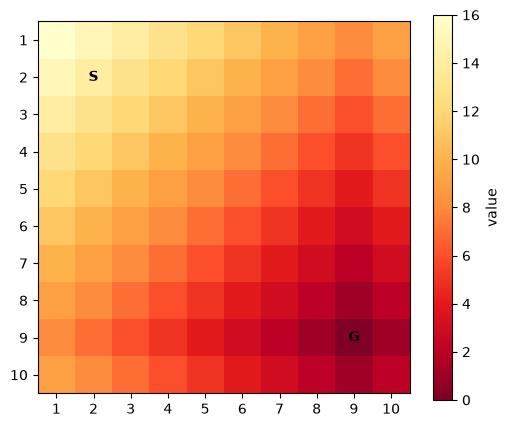

In [4]:
rows, columns = np.indices((n, n))
h_manhattan = np.abs(rows - goal[0]) + np.abs(columns - goal[1])
print(h_manhattan)
show_values(h_manhattan)

The algorithm will follow the color gradient from light yellow to dark red.

## A* with Manhattan heuristic

Calculate $f(n) = g(n) + h(n)$.

[[18 16 16 16 16 16 16 16 16 18]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [16 14 14 14 14 14 14 14 14 16]
 [18 16 16 16 16 16 16 16 16 18]]


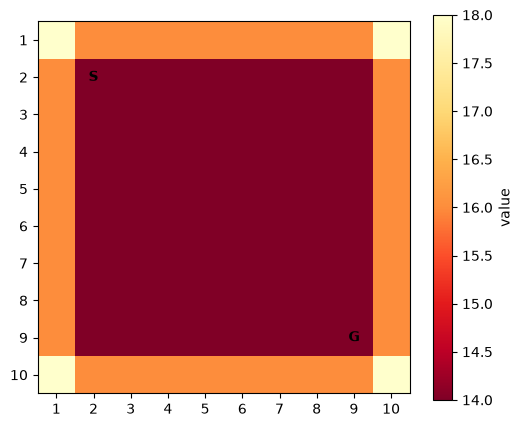

In [5]:
g = np.abs(rows - start[0]) + np.abs(columns - start[1])
f = g + h_manhattan
print(f)
show_values(f)

**Note:** In Manhattan geometry, all paths that go directly from $S$ to $G$ are optimal and have the same distance. Even with a perfect heuristic, the agent faces a plateau of positions with exactly the same $f(n) = C^*$. All directions are tied, so the tie-breaking strategy is important. For A* search with a reached data structure, this means that all states in the red square will be explored leading to very inefficient search!

[Amit Patel's discussion of heuristics](http://theory.stanford.edu/~amitp/GameProgramming/Heuristics.html) describes this and other issues and suggests increasing the value of $h(n)$ by a small factor, leading to weighted A* search.

## Weighted A* Search

Use $f(n) = g(n) + W \times h(n)$, with $W > 0$. For $W>1$, this is not guaranteed to be optimal because the weighted heuristic may become inadmissible, but it can reduce search time and memory. First, inflate the heuristic by 10%.

[[19.6 17.5 17.4 17.3 17.2 17.1 17.  16.9 16.8 18.9]
 [17.5 15.4 15.3 15.2 15.1 15.  14.9 14.8 14.7 16.8]
 [17.4 15.3 15.2 15.1 15.  14.9 14.8 14.7 14.6 16.7]
 [17.3 15.2 15.1 15.  14.9 14.8 14.7 14.6 14.5 16.6]
 [17.2 15.1 15.  14.9 14.8 14.7 14.6 14.5 14.4 16.5]
 [17.1 15.  14.9 14.8 14.7 14.6 14.5 14.4 14.3 16.4]
 [17.  14.9 14.8 14.7 14.6 14.5 14.4 14.3 14.2 16.3]
 [16.9 14.8 14.7 14.6 14.5 14.4 14.3 14.2 14.1 16.2]
 [16.8 14.7 14.6 14.5 14.4 14.3 14.2 14.1 14.  16.1]
 [18.9 16.8 16.7 16.6 16.5 16.4 16.3 16.2 16.1 18.2]]


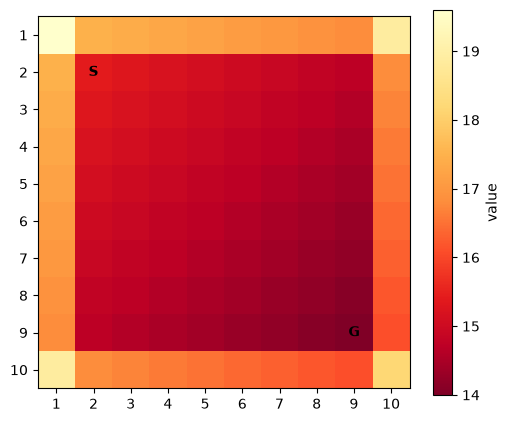

In [6]:
f = g + 1.10 * h_manhattan
print(f)
show_values(f)

The weighting create a slight gradient that leads directly from $S$ to $G$. Now try $W=5$. As $W$ increases, weighted A* approaches greedy best-first search (GBFS), which completely ignores $g(n)$.

[[82 76 72 68 64 60 56 52 48 54]
 [76 70 66 62 58 54 50 46 42 48]
 [72 66 62 58 54 50 46 42 38 44]
 [68 62 58 54 50 46 42 38 34 40]
 [64 58 54 50 46 42 38 34 30 36]
 [60 54 50 46 42 38 34 30 26 32]
 [56 50 46 42 38 34 30 26 22 28]
 [52 46 42 38 34 30 26 22 18 24]
 [48 42 38 34 30 26 22 18 14 20]
 [54 48 44 40 36 32 28 24 20 26]]


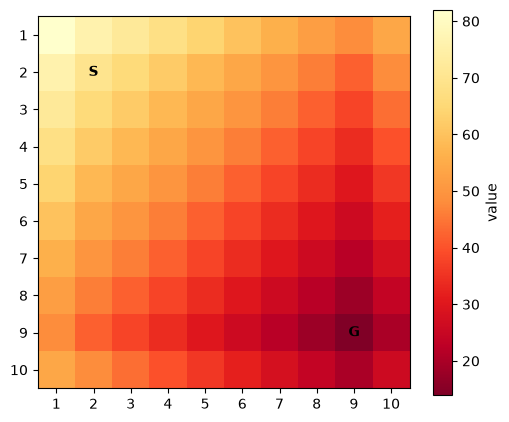

In [7]:
f = g + 5 * h_manhattan
print(f)
show_values(f)

Using $W<1$ makes the search behave more like uniform-cost search (BFS when every step has the same cost). This leads to exploring the area around $S$ first and very inefficient search.

[[10.   8.5  9.   9.5 10.  10.5 11.  11.5 12.  13.5]
 [ 8.5  7.   7.5  8.   8.5  9.   9.5 10.  10.5 12. ]
 [ 9.   7.5  8.   8.5  9.   9.5 10.  10.5 11.  12.5]
 [ 9.5  8.   8.5  9.   9.5 10.  10.5 11.  11.5 13. ]
 [10.   8.5  9.   9.5 10.  10.5 11.  11.5 12.  13.5]
 [10.5  9.   9.5 10.  10.5 11.  11.5 12.  12.5 14. ]
 [11.   9.5 10.  10.5 11.  11.5 12.  12.5 13.  14.5]
 [11.5 10.  10.5 11.  11.5 12.  12.5 13.  13.5 15. ]
 [12.  10.5 11.  11.5 12.  12.5 13.  13.5 14.  15.5]
 [13.5 12.  12.5 13.  13.5 14.  14.5 15.  15.5 17. ]]


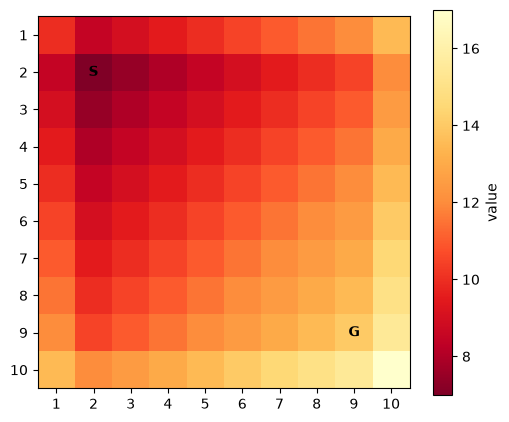

In [8]:
f = g + 0.5 * h_manhattan
print(f)
show_values(f)

## Greedy Best-First Search with Euclidean Distance for $h(n)$

Euclidean distance is the $L_2$ norm: $L_2(a,b) = \sqrt{(a_x-b_x)^2 + (a_y-b_y)^2}$. It is not perfect when the true cost follows Manhattan distance, but it is admissible: $h(n) \leq h^*(n)$.

[[11.3137 10.6301 10.      9.434   8.9443  8.544   8.2462  8.0623  8.
   8.0623]
 [10.6301  9.8995  9.2195  8.6023  8.0623  7.6158  7.2801  7.0711  7.
   7.0711]
 [10.      9.2195  8.4853  7.8102  7.2111  6.7082  6.3246  6.0828  6.
   6.0828]
 [ 9.434   8.6023  7.8102  7.0711  6.4031  5.831   5.3852  5.099   5.
   5.099 ]
 [ 8.9443  8.0623  7.2111  6.4031  5.6569  5.      4.4721  4.1231  4.
   4.1231]
 [ 8.544   7.6158  6.7082  5.831   5.      4.2426  3.6056  3.1623  3.
   3.1623]
 [ 8.2462  7.2801  6.3246  5.3852  4.4721  3.6056  2.8284  2.2361  2.
   2.2361]
 [ 8.0623  7.0711  6.0828  5.099   4.1231  3.1623  2.2361  1.4142  1.
   1.4142]
 [ 8.      7.      6.      5.      4.      3.      2.      1.      0.
   1.    ]
 [ 8.0623  7.0711  6.0828  5.099   4.1231  3.1623  2.2361  1.4142  1.
   1.4142]]


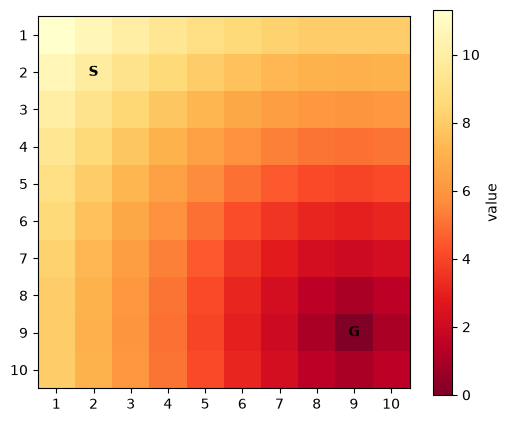

In [9]:
h_euclidean = np.hypot(rows - goal[0], columns - goal[1])
print(h_euclidean)
show_values(h_euclidean)

## A* with Euclidean Distance for $h(n)$

[[13.3137 11.6301 12.     12.434  12.9443 13.544  14.2462 15.0623 16.
  17.0623]
 [11.6301  9.8995 10.2195 10.6023 11.0623 11.6158 12.2801 13.0711 14.
  15.0711]
 [12.     10.2195 10.4853 10.8102 11.2111 11.7082 12.3246 13.0828 14.
  15.0828]
 [12.434  10.6023 10.8102 11.0711 11.4031 11.831  12.3852 13.099  14.
  15.099 ]
 [12.9443 11.0623 11.2111 11.4031 11.6569 12.     12.4721 13.1231 14.
  15.1231]
 [13.544  11.6158 11.7082 11.831  12.     12.2426 12.6056 13.1623 14.
  15.1623]
 [14.2462 12.2801 12.3246 12.3852 12.4721 12.6056 12.8284 13.2361 14.
  15.2361]
 [15.0623 13.0711 13.0828 13.099  13.1231 13.1623 13.2361 13.4142 14.
  15.4142]
 [16.     14.     14.     14.     14.     14.     14.     14.     14.
  16.    ]
 [17.0623 15.0711 15.0828 15.099  15.1231 15.1623 15.2361 15.4142 16.
  17.4142]]


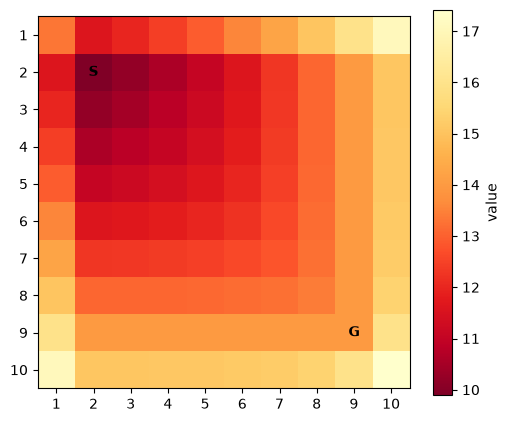

In [10]:
f = g + h_euclidean
print(f)
show_values(f)

**Note:** Euclidean and Manhattan geometry do not mix well here; the gradient is actually from the goal toward the start.
          A* expands every node with $f(n)<C^*$ and some nodes with $f(n)=C^*$. These nodes are shown in black below.

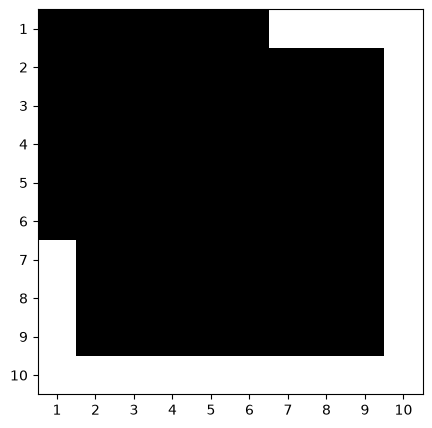

In [11]:
optimal_cost = f[tuple(goal)]
show_values(f <= optimal_cost, cmap="Greys", colorbar=False)

# Conclusion

We need to be careful when choosing heuristics to make sure that we still create a clear gradient for A* to follow. Otherwise, we will end up with an algorithm that is as inefficient as BFS. 

# Bài 6 – Ảnh hưởng của heuristic

Các bản đồ $h(n)$ và $f(n)$ ở trên chỉ là giá trị *tĩnh*. Phần này chạy thật GBFS và A\* với từng heuristic để đo số nút mở rộng và chi phí đường đi, trên mê cung rỗng $10 \times 10$ ở trên và trên các mê cung của bài tập.

**Cài đặt.** Best-first search dạng graph search (có `reached`), kiểm tra đích khi lấy nút ra khỏi frontier. Khi hai nút có cùng $f$, tham số `tie` chọn nút được thêm **sau cùng** (`"LIFO"`, mặc định) hoặc **trước nhất** (`"FIFO"`).

In [12]:
import heapq
import pandas as pd

MOVES = [(-1, 0), (0, 1), (1, 0), (0, -1)]   # N, E, S, W


def neighbors(grid, pos):
    rows_, cols_ = grid.shape
    for dr, dc in MOVES:
        r, c = pos[0] + dr, pos[1] + dc
        if 0 <= r < rows_ and 0 <= c < cols_ and grid[r, c] != "X":
            yield (r, c)


def search(grid, start, goal, h, strategy="A*", tie="LIFO"):
    """GBFS (f = h) hoặc A* (f = g + h). Trả về chi phí, số nút mở rộng và các ô đã mở rộng."""
    start, goal = tuple(int(v) for v in start), tuple(int(v) for v in goal)
    count = 0
    g = {start: 0}
    parent = {start: None}
    frontier = [(h(start), 0, start)]
    expanded = []
    closed = set()
    while frontier:
        _, _, s = heapq.heappop(frontier)
        if s in closed:
            continue
        if s == goal:
            path = [s]
            while parent[path[-1]] is not None:
                path.append(parent[path[-1]])
            return {"cost": g[s], "expanded": len(expanded), "explored": expanded, "path": path[::-1]}
        closed.add(s)
        expanded.append(s)
        for t in neighbors(grid, s):
            new_g = g[s] + 1
            if t not in g or (strategy == "A*" and new_g < g[t]):
                g[t], parent[t] = new_g, s
                closed.discard(t)
                count += 1
                f = h(t) if strategy == "GBFS" else new_g + h(t)
                heapq.heappush(frontier, (f, -count if tie == "LIFO" else count, t))
    return {"cost": None, "expanded": len(expanded), "explored": expanded, "path": []}


def make_heuristics(goal):
    gr, gc = int(goal[0]), int(goal[1])
    return {
        "Manhattan": lambda p: abs(p[0] - gr) + abs(p[1] - gc),
        "Euclidean": lambda p: ((p[0] - gr) ** 2 + (p[1] - gc) ** 2) ** 0.5,
    }

## So sánh Manhattan và Euclidean cho GBFS và A\* trên mê cung rỗng

Màu xám: ô đã mở rộng; đỏ: đường đi tìm được.

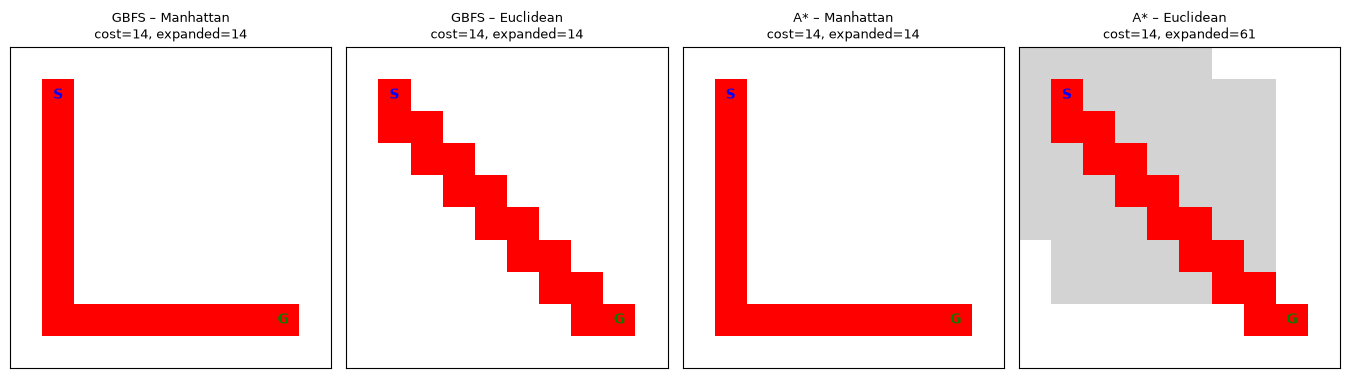

,cost,expanded
GBFS – Manhattan,14,14
GBFS – Euclidean,14,14
A* – Manhattan,14,14
A* – Euclidean,14,61


In [13]:
from matplotlib import colors as mcolors


def show_runs(grid, start, goal, runs, ncols=None):
    """Vẽ vùng đã mở rộng (xám) và đường đi (đỏ) của nhiều lần chạy."""
    ncols = ncols or len(runs)
    nrows = -(-len(runs) // ncols)
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.4 * ncols, 3.4 * nrows * grid.shape[0] / grid.shape[1] + 0.6))
    cmap = mcolors.ListedColormap(["white", "black", "lightgray", "red"])
    for ax, (title, res) in zip(np.atleast_1d(axes).flat, runs.items()):
        img = np.where(grid == "X", 1, 0)
        for p in res["explored"]:
            img[p] = 2
        for p in res["path"]:
            img[p] = 3
        ax.imshow(img, cmap=cmap, vmin=0, vmax=3)
        ax.text(start[1], start[0], "S", ha="center", va="center", color="blue", fontweight="bold")
        ax.text(goal[1], goal[0], "G", ha="center", va="center", color="green", fontweight="bold")
        ax.set_title(f"{title}\ncost={res['cost']}, expanded={res['expanded']}", fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])
    plt.tight_layout()
    plt.show()


H = make_heuristics(goal)
runs = {f"{alg} – {name}": search(maze, start, goal, h, alg)
        for alg in ["GBFS", "A*"] for name, h in H.items()}
show_runs(maze, start, goal, runs)
pd.DataFrame({k: {"cost": v["cost"], "expanded": v["expanded"]} for k, v in runs.items()}).T

**Vai trò của hòa điểm (plateau).** Với A\* + Manhattan trên mê cung rỗng, mọi ô trong hình chữ nhật giữa `S` và `G` có cùng $f(n) = C^* = 14$. Nếu hòa điểm được phá theo FIFO (nút cũ trước), A\* mở rộng gần như toàn bộ hình chữ nhật đó – đúng như nhận xét trong phần trên của notebook. Ưu tiên nút mới nhất (LIFO) hoặc nhân $h$ với hệ số rất nhỏ $1 + \varepsilon$ đều tạo ra "độ dốc" để A\* đi thẳng tới đích. Kết quả đo: FIFO mở rộng 63 nút, LIFO và $(1+1/p)h$ chỉ 14 nút (đúng bằng số bước), còn Euclidean mở rộng 74 nút – gần như toàn bộ vùng $f(n) \le C^*$.

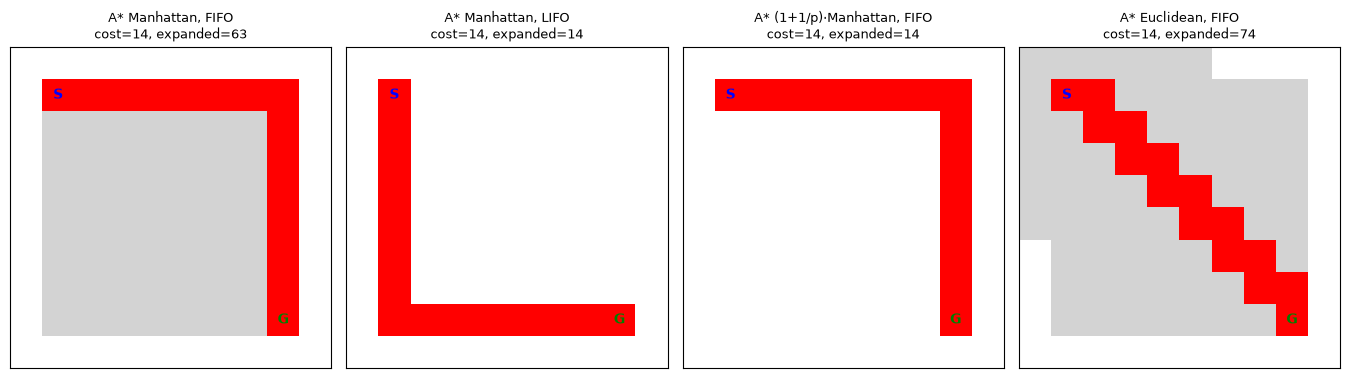

In [14]:
manh = H["Manhattan"]
eps = 1 / (n * n)     # 1/p với p = số ô, lớn hơn mọi độ dài đường đi
tie_runs = {
    "A* Manhattan, FIFO": search(maze, start, goal, manh, "A*", tie="FIFO"),
    "A* Manhattan, LIFO": search(maze, start, goal, manh, "A*", tie="LIFO"),
    "A* (1+1/p)·Manhattan, FIFO": search(maze, start, goal, lambda p: (1 + eps) * manh(p), "A*", tie="FIFO"),
    "A* Euclidean, FIFO": search(maze, start, goal, H["Euclidean"], "A*", tie="FIFO"),
}
show_runs(maze, start, goal, tie_runs)

## Heuristic đề xuất: landmark (ALT / differential heuristic)

Manhattan và Euclidean đều **bỏ qua tường**, nên trong mê cung có ngõ cụt (L maze, open maze) chúng có thể kéo tác tử vào sai hướng. Đề xuất heuristic **landmark**: chọn trước vài ô mốc $L$ và tính sẵn (bằng BFS một lần cho mỗi mốc) khoảng cách thật $d(L, \cdot)$ tới mọi ô. Theo bất đẳng thức tam giác:

$$h_{ALT}(n) = \max_{L} \, \big| d(L, G) - d(L, n) \big| \;\le\; d(n, G) = h^*(n).$$

Kết hợp với Manhattan: $h(n) = \max\big(h_{\text{Manhattan}}(n),\, h_{ALT}(n)\big)$ – lấy max của các heuristic chấp nhận được vẫn chấp nhận được, và trội hơn (dominates) từng thành phần. Cái giá: tiền xử lý $O(k \cdot n)$ thời gian và bộ nhớ cho $k$ mốc, hợp lý khi cùng một bản đồ được dùng cho nhiều truy vấn.

Bảng dưới so sánh các heuristic trên các mê cung bài tập (A\* với tie-breaking LIFO; GBFS cho tham khảo). $h^*$ (khoảng cách thật, tính bằng BFS ngược từ `G`) là cận lý tưởng: A\* với $h^*$ chỉ mở rộng các ô trên đường đi tối ưu.

In [15]:
from collections import deque


def bfs_distances(grid, source):
    """Khoảng cách thật từ source tới mọi ô (BFS trên lưới)."""
    source = tuple(int(v) for v in source)
    dist = {source: 0}
    queue = deque([source])
    while queue:
        s = queue.popleft()
        for t in neighbors(grid, s):
            if t not in dist:
                dist[t] = dist[s] + 1
                queue.append(t)
    return dist


def landmark_heuristic(grid, goal, k=2):
    """h(n) = max(Manhattan, max_L |d(L,G) - d(L,n)|) với k mốc chọn theo kiểu "farthest point"."""
    goal = tuple(int(v) for v in goal)
    manh = make_heuristics(goal)["Manhattan"]
    landmarks, tables = [], []
    far = bfs_distances(grid, goal)
    for _ in range(k):
        # mốc tiếp theo: ô xa nhất so với các mốc đã chọn (và đích)
        lm = max(far, key=far.get)
        d = bfs_distances(grid, lm)
        landmarks.append(lm)
        tables.append(d)
        far = {s: min(far[s], d[s]) for s in far}
    return lambda p: max(manh(p), *(abs(d[goal] - d.get(p, 0)) for d in tables)), landmarks


def load(file):
    with open(file) as f:
        grid = np.array([list(row) for row in f.read().split("\n") if row])
    s = np.argwhere(grid == "S")[0]
    g = np.argwhere(grid == "G")[0]
    return grid, tuple(int(v) for v in s), tuple(int(v) for v in g)


test_mazes = {"empty 10x10 (above)": (maze, tuple(int(v) for v in start), tuple(int(v) for v in goal))}
for file in ["empty_maze.txt", "L_maze.txt", "open_maze.txt", "medium_maze.txt", "loops_maze.txt"]:
    test_mazes[file.replace(".txt", "")] = load(file)

records = []
alt_runs = {}
for name, (grid, s, gp) in test_mazes.items():
    hs = make_heuristics(gp)
    hs["Landmark (ALT)"], _ = landmark_heuristic(grid, gp)
    exact = bfs_distances(grid, gp)
    hs["h* (exact)"] = lambda p, exact=exact: exact[p]
    for hname, h in hs.items():
        for alg in ["GBFS", "A*"]:
            r = search(grid, s, gp, h, alg)
            records.append({"maze": name, "heuristic": hname, "algorithm": alg,
                         "cost": r["cost"], "expanded": r["expanded"]})
            if name == "L_maze" and alg == "A*":
                alt_runs[f"A* – {hname}"] = r

res_df = pd.DataFrame(records)
res_df.pivot_table(index=["maze", "heuristic"], columns="algorithm", aggfunc="first",
                   values=["cost", "expanded"], sort=False)

cost     expanded     
algorithm                          GBFS  A*     GBFS   A*
maze                heuristic                            
empty 10x10 (above) Manhattan        14  14       14   14
                    Euclidean        14  14       14   61
                    Landmark (ALT)   14  14       14   14
                    h* (exact)       14  14       14   14
empty_maze          Manhattan        14  14       14   14
                    Euclidean        14  14       14   61
                    Landmark (ALT)   14  14       14   14
                    h* (exact)       14  14       14   14
L_maze              Manhattan        16  16       33   40
                    Euclidean        20  16       33   62
                    Landmark (ALT)   22  16       23   29
                    h* (exact)       16  16       16   16
open_maze           Manhattan        54  54      211  211
                    Euclidean        54  54       54  516
                    Landmark (ALT)   54  54       54   54
                    h* (exact)       54  54       54   54
medium_maze         Manhattan       152  68      155  217
                    Euclidean       152  68      159  224
                    Landmark (ALT)   74  68       84   82
                    h* (exact)       68  68       68   68
loops_maze          Manhattan        41  23       51   51
                    Euclidean        35  23       51   57
                    Landmark (ALT)   23  23       23   23
                    h* (exact)       23  23       23   23

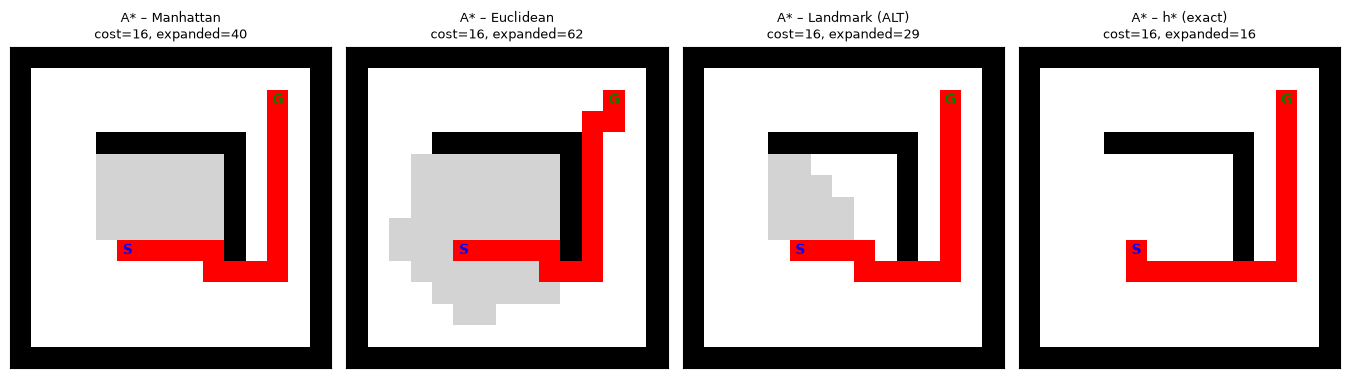

In [16]:
grid, s, gp = test_mazes["L_maze"]
show_runs(grid, s, gp, alt_runs)

## Trả lời Bài 6

**1. Quan sát bản đồ $h(n)$ và $f(n)$ trong mê cung rỗng.**

* $h_{\text{Manhattan}}$ giảm đều 1 đơn vị sau mỗi bước về phía `G`, nên GBFS đi thẳng xuống "dốc" màu tới đích.
* Với A\* + Manhattan, mọi ô trong hình chữ nhật giữa `S` và `G` có $f(n) = 14 = C^*$ – một **cao nguyên** (plateau). Heuristic đã hoàn hảo ($h = h^*$) nhưng $f$ không phân biệt được các ô này, nên hiệu quả hoàn toàn phụ thuộc cách phá hòa: FIFO mở rộng gần như cả hình chữ nhật, còn LIFO hoặc $(1+\varepsilon)h$ đi thẳng tới đích với 14 nút.
* Với A\* + Euclidean, $f$ **tăng** dần từ `S` về phía `G` (vì $h_E$ đánh giá thấp chi phí, phần thiếu hụt lớn nhất ở giữa đường chéo). A\* phải mở rộng mọi ô có $f(n) < C^*$, tức gần như toàn bộ vùng màu đen trong hình cuối của phần trên.

**2. So sánh Manhattan và Euclidean cho GBFS và A\*** (số liệu ở bảng trên):

* **GBFS:** trên mê cung rỗng cả hai đều dẫn GBFS thẳng tới đích (14 nút). Trong mê cung có tường, GBFS không bảo đảm tối ưu với cả hai heuristic (medium: 152 so với 68; loops: 41 với Manhattan, 35 với Euclidean so với 23); kết quả phụ thuộc việc heuristic có "lừa" tác tử vào ngõ cụt hay không. Trên open maze, GBFS-Euclidean tình cờ đi đúng hướng ngay (54 nút) còn GBFS-Manhattan bị kéo vào căn phòng phía trên (211 nút).
* **A\*:** cả hai đều cho chi phí tối ưu (đều chấp nhận được), nhưng **Manhattan mở rộng ít nút hơn hẳn** – trên mê cung rỗng $10\times10$ A\*-Euclidean mở rộng 61 nút so với 14 của A\*-Manhattan, trên open maze là 516 so với 211, L maze 62 so với 40. Lý do: $h_E \le h_M \le h^*$ – Manhattan **trội hơn** (dominates) Euclidean, mà A\* với heuristic trội hơn không bao giờ mở rộng nhiều nút hơn (trừ chênh lệch do phá hòa).

**3. Vì sao Manhattan phù hợp hơn với lưới 4 hướng?** Khi chỉ đi N/E/S/W với chi phí 1, mỗi bước chỉ thay đổi hàng **hoặc** cột 1 đơn vị, nên số bước tối thiểu khi không có tường *chính bằng* $|\Delta r| + |\Delta c|$. Manhattan là chi phí chính xác của bài toán nới lỏng "bỏ tường", nên vừa **chấp nhận được** vừa **nhất quán** ($|h(n) - h(n')| \le 1 = c(n,n')$) và là heuristic chặt nhất có thể nếu không xét tường. Euclidean là chi phí của bài toán nới lỏng hơn nữa (được đi chéo, đi theo đường thẳng), nên nhỏ hơn đáng kể – đặc biệt theo phương chéo, $h_E = h_M/\sqrt{2}$ – dẫn tới kém thông tin và nhiều nút mở rộng hơn. Euclidean chỉ phù hợp khi tác tử được di chuyển tự do/theo mọi hướng.

**4. Heuristic đề xuất và điều kiện tối ưu.**

* *Landmark (ALT)*, kết hợp $\max$ với Manhattan (cài đặt ở trên): tính đến tường nên A\* mở rộng ít nút hơn hẳn Manhattan (L: 29 so với 40; open: 54 so với 211; medium: 82 so với 217; loops: 23 so với 51) mà vẫn cho chi phí tối ưu. Trên mê cung rỗng nó trùng với Manhattan (không có tường để khai thác).
* *Manhattan × $(1 + 1/p)$* với $p$ lớn hơn độ dài đường đi dài nhất có thể (ví dụ $p$ = số ô trống): về hình thức không chấp nhận được, nhưng Weighted A\* bảo đảm chi phí $\le (1 + 1/p)\,C^* < C^* + 1$; vì chi phí là số nguyên nên lời giải vẫn **tối ưu**, đồng thời phá được cao nguyên $f = C^*$.

*Điều kiện để A\* bảo đảm tối ưu:*

1. $h(n) \ge 0$ và $h(G) = 0$ tại mọi trạng thái đích.
2. **Chấp nhận được (admissible):** $h(n) \le h^*(n)$ với mọi $n$ – không bao giờ đánh giá cao chi phí thật tới đích. Đủ cho A\* dạng tree search (hoặc graph search có mở lại nút).
3. **Nhất quán (consistent / monotone):** $h(n) \le c(n, a, n') + h(n')$ với mọi cạnh $(n, a, n')$. Nhất quán ⇒ chấp nhận được, và bảo đảm $f$ không giảm dọc mọi đường đi, nên A\* graph search với `reached` mà không cần mở lại nút vẫn tối ưu. Manhattan, Euclidean, ALT và $\max$ của chúng đều nhất quán.

Ngoài ra: heuristic càng **trội** (lớn hơn nhưng vẫn $\le h^*$) thì A\* càng mở rộng ít nút; còn chi phí tính $h$ phải đủ rẻ so với số nút tiết kiệm được ($h^*$ tính bằng BFS là ví dụ cực đoan: chỉ mở rộng đường đi tối ưu nhưng tốn công bằng chính một lần tìm kiếm đầy đủ).